# Prompt Tuning Demo

Clusters a set of questions, extracts keywords from each cluster, and
suggests additions to a base prompt. Uses the same 100 maintenance
questions from the validation notebook.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import load_questions
from src.embeddings import Embedder
from src.prompt_tuning import cluster_questions, extract_keywords, suggest_prompt

questions = load_questions(ROOT / "data" / "maintenance_questions.csv", column="Questions")
print(f"Loaded {len(questions)} questions.")

Loaded 100 questions.


In [2]:
base_prompt = "Generate questions for Industry 4.0 maintenance readiness assessment"

result = suggest_prompt(
    base_prompt=base_prompt,
    questions=questions,
    n_clusters="auto",
    top_n_keywords=6,
)

print(f"Auto-selected clusters: {result['n_clusters']}")
print()
print("Keywords per cluster:")
for lab, kws in result["keywords"].items():
    print(f"  cluster {lab}: {kws}")
print()
print("Refined prompt:")
print(result["refined_prompt"])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

C:\Users\gaura\OneDrive\Desktop\New Beginnings\assessai-toolkit\venv\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Auto-selected clusters: 5

Keywords per cluster:
  cluster 1: ['maintenance', 'strategy', 'maintenance strategy', 'does', 'industry', 'effectiveness']
  cluster 3: ['maintenance', 'digital', 'used', 'digital twins', 'twins', 'tools']
  cluster 0: ['maintenance', 'use', 'time', 'real', 'real time', 'iot']
  cluster 4: ['maintenance', 'data', 'maintenance data', 'use', 'historical', 'security']
  cluster 2: ['maintenance', 'systems', 'ai', 'management', 'integrated', 'decision']

Refined prompt:
Generate questions for Industry 4.0 maintenance readiness assessment. Include questions covering: terms related to maintenance, use, time, real, real time, iot; terms related to maintenance, strategy, maintenance strategy, does, industry, effectiveness; terms related to maintenance, systems, ai, management, integrated, decision; terms related to maintenance, digital, used, digital twins, twins, tools; terms related to maintenance, data, maintenance data, use, historical, security.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

C:\Users\gaura\OneDrive\Desktop\New Beginnings\assessai-toolkit\venv\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


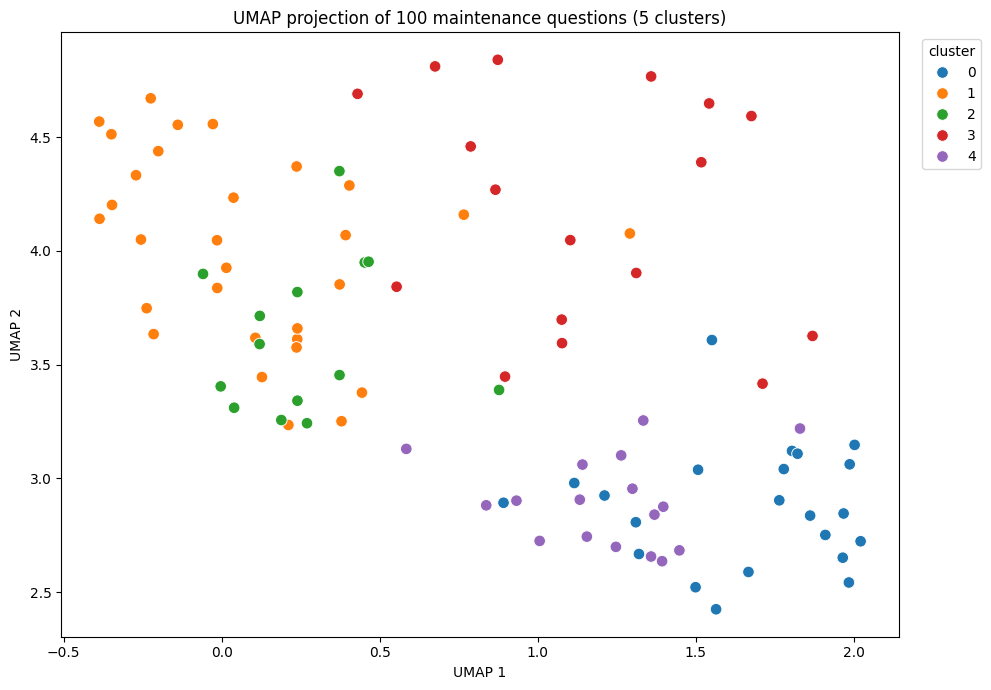

Saved: C:\Users\gaura\OneDrive\Desktop\New Beginnings\assessai-toolkit\docs\clustering.png


In [3]:
cluster_out = cluster_questions(questions, embedder=Embedder(), n_clusters=result["n_clusters"])
reduced = cluster_out["reduced"]
labels = np.array(cluster_out["labels"])

docs = ROOT / "docs"
docs.mkdir(exist_ok=True)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=reduced[:, 0], y=reduced[:, 1], hue=labels, palette="tab10", s=70)
plt.title(f"UMAP projection of 100 maintenance questions ({result['n_clusters']} clusters)")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(docs / "clustering.png", dpi=120, bbox_inches="tight")
plt.show()

print("Saved:", docs / "clustering.png")

In [4]:
out_dir = ROOT / "docs"
out_dir.mkdir(exist_ok=True)

summary_path = out_dir / "prompt_tuning_summary.txt"
with open(summary_path, "w", encoding="utf-8") as f:
    f.write("Base prompt:\n" + base_prompt + "\n\n")
    f.write(f"Clusters: {result['n_clusters']}\n\n")
    f.write("Keywords per cluster:\n")
    for lab, kws in result["keywords"].items():
        f.write(f"  cluster {lab}: {kws}\n")
    f.write("\nRefined prompt:\n" + result["refined_prompt"] + "\n")

print("Saved:", summary_path)

Saved: C:\Users\gaura\OneDrive\Desktop\New Beginnings\assessai-toolkit\docs\prompt_tuning_summary.txt
